# Wine Quality Prediction
## Machine Learning Practical

**Objective:** Predict whether red wine is high quality or normal quality using its physicochemical properties.

This notebook follows the supplied case study. For this implementation, wine quality scores of **7 or above** are labelled as high quality (`1`), and scores below 7 are labelled as normal quality (`0`). This threshold is an explicit project assumption.

**Dataset required:** `winequality-red.csv` (semicolon-separated CSV file).

## 1. Import libraries



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

%matplotlib inline
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload and load the dataset



In [ ]:
from google.colab import files
uploaded = files.upload()

# Use the uploaded CSV file
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("Please upload the winequality-red.csv dataset.")

file_name = csv_files[0]
df = pd.read_csv(file_name, sep=";")

print("Loaded file:", file_name)
df.head()

Saving winequality.csv to winequality.csv
Loaded file: winequality.csv


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Explore the dataset


In [ ]:
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nStatistical summary:")
display(df.describe())

print("\\nMissing values per column:")
display(df.isnull().sum())

print("\\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (1599, 12)
\nColumn names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 n

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


\nMissing values per column:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


\nDuplicate rows: 240


## 4. Exploratory Data Analysis (EDA)



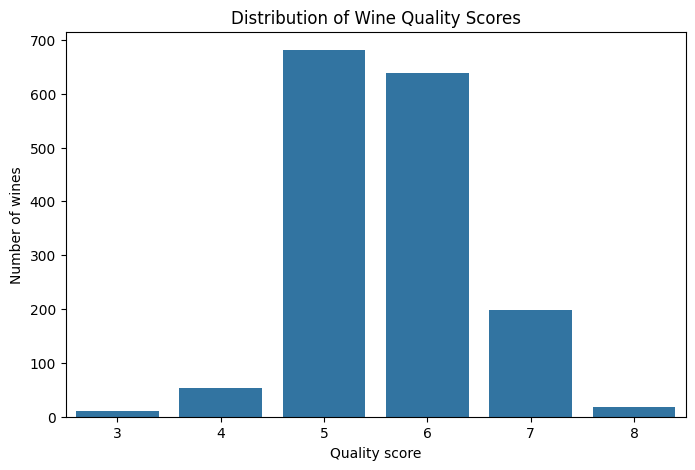

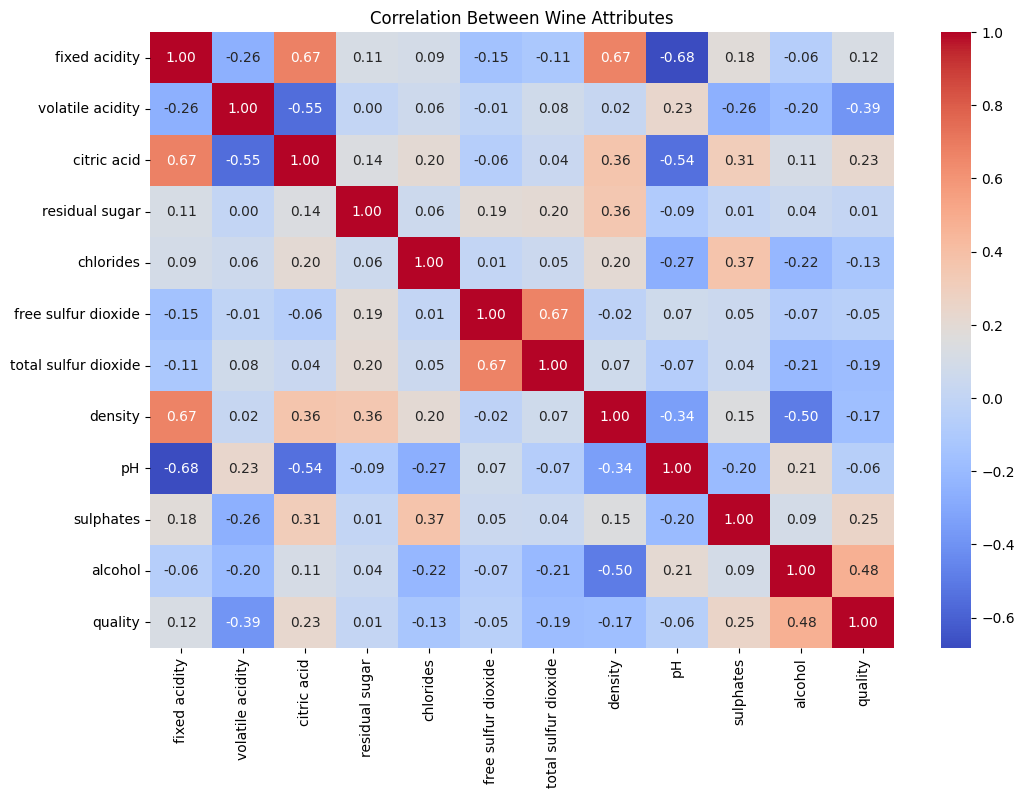

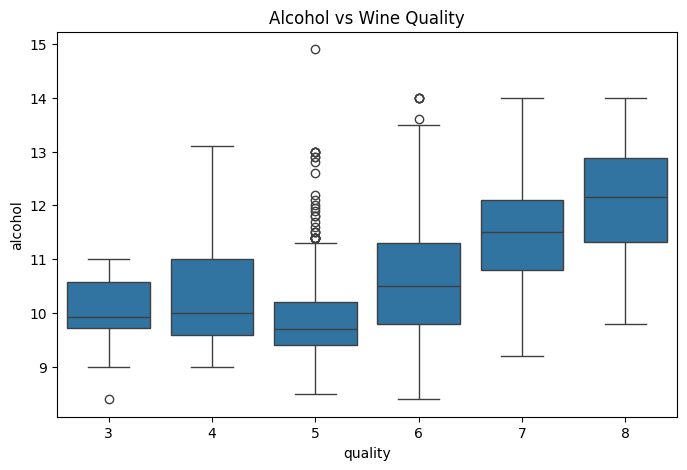

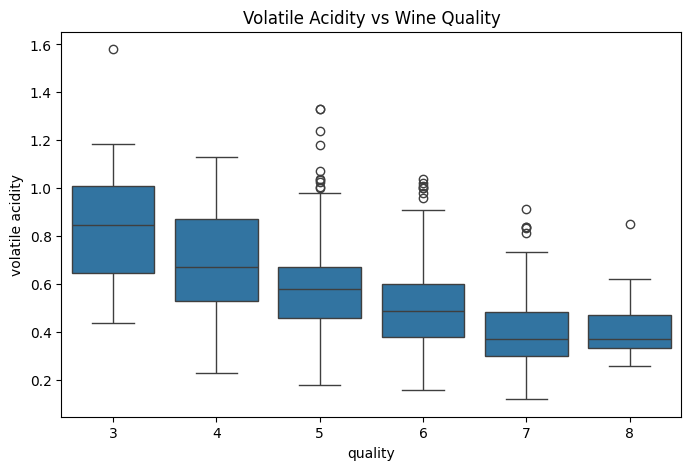

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Wine Attributes")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol vs Wine Quality")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="volatile acidity")
plt.title("Volatile Acidity vs Wine Quality")
plt.show()

## 5. Prepare the data



- `1` = high quality (quality score ≥ 7)
- `0` = normal quality (quality score < 7)



In [ ]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Fill missing numeric values, if any
numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].median())

# Separate features and target
X = df.drop(columns=["quality"])
y = (df["quality"] >= 7).astype(int)

print("Class counts (0 = normal, 1 = high quality):")
display(y.value_counts().sort_index())

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Class counts (0 = normal, 1 = high quality):


,count
quality,
0,1175
1,184


Features shape: (1359, 11)
Target shape: (1359,)


## 6. Split the dataset



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (1087, 11)
Testing features: (272, 11)


## 7. Train the Random Forest model



In [ ]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


## 8. Make predictions and evaluate the model



In [ ]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.8860294117647058
Precision: 0.6875
Recall   : 0.2972972972972973
F1-score : 0.41509433962264153
ROC-AUC  : 0.8821161587119034
\nClassification report:
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       235
           1       0.69      0.30      0.42        37

    accuracy                           0.89       272
   macro avg       0.79      0.64      0.68       272
weighted avg       0.87      0.89      0.87       272



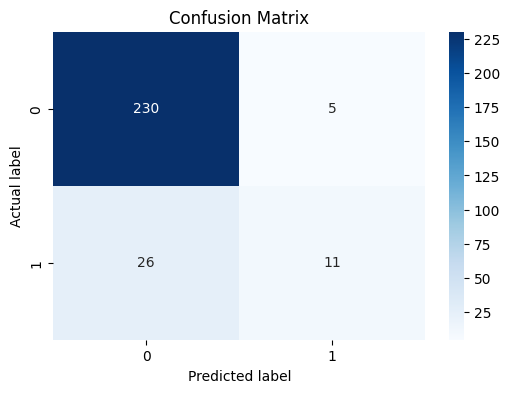

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.show()

## 9. Feature importance



,Feature,Importance
10,alcohol,0.226725
9,sulphates,0.145303
1,volatile acidity,0.098126
2,citric acid,0.098034
6,total sulfur dioxide,0.073788
7,density,0.072295
0,fixed acidity,0.071155
4,chlorides,0.065674
5,free sulfur dioxide,0.055261
8,pH,0.054484


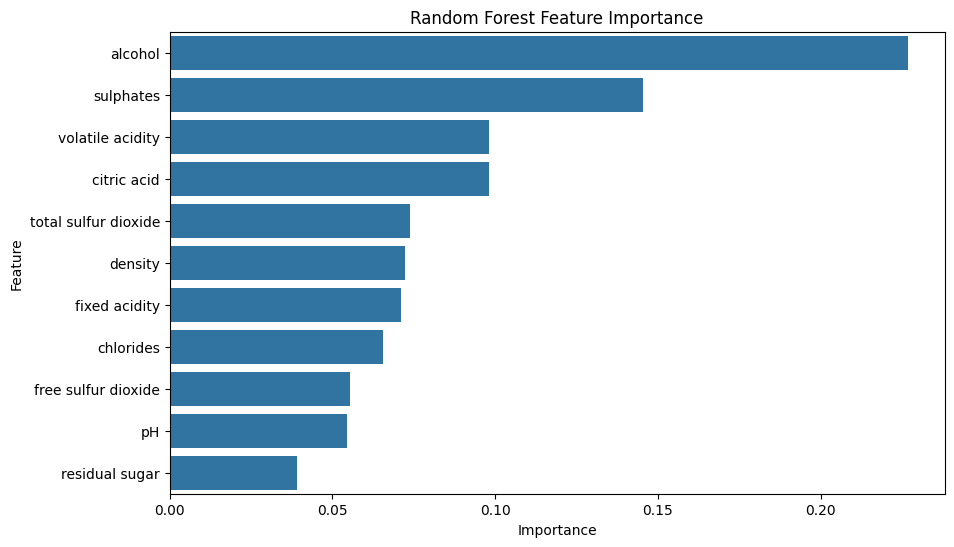

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.show()

## 10. Predict the quality of a new wine



In [ ]:
new_wine = pd.DataFrame([{
    "fixed acidity": 7.4,
    "volatile acidity": 0.50,
    "citric acid": 0.30,
    "residual sugar": 2.0,
    "chlorides": 0.07,
    "free sulfur dioxide": 15,
    "total sulfur dioxide": 40,
    "density": 0.996,
    "pH": 3.3,
    "sulphates": 0.65,
    "alcohol": 11.5
}])

# Reorder columns to match the training data
new_wine = new_wine[X.columns]

prediction = model.predict(new_wine)[0]
probability = model.predict_proba(new_wine)[0, 1]

if prediction == 1:
    print("Prediction: HIGH-QUALITY WINE")
else:
    print("Prediction: NORMAL-QUALITY WINE")

print(f"Predicted probability of high quality: {probability:.2%}")

Prediction: NORMAL-QUALITY WINE
Predicted probability of high quality: 9.00%


## 11. Challenges faced during the project



1. **Understanding the dataset:** The dataset contains several chemical attributes. I reviewed the attribute descriptions and used summary statistics and visualizations to understand them.
2. **Duplicate and missing records:** Duplicate rows and possible missing values can affect analysis. I checked both, removed duplicates, and filled numeric missing values with the median where needed.
3. **Class imbalance:** There may be fewer high-quality wines than normal-quality wines. I used stratified splitting and `class_weight="balanced"` to help address this.
4. **Choosing a model:** Selecting an appropriate algorithm was challenging. I chose Random Forest because it combines multiple decision trees.
5. **Evaluating performance:** Accuracy alone can hide poor performance on the smaller class. I also evaluated precision, recall, F1-score, ROC-AUC, and the confusion matrix.
6. **Identifying influential attributes:** It was not obvious which attributes mattered most. I examined Random Forest feature importance.
7. **Predicting new records:** New input must have the same feature columns as the training data. I used a DataFrame and reordered its columns to match `X`.

## 12. Conclusion

This project demonstrates a Machine Learning workflow for classifying red wine as high quality or normal quality using physicochemical measurements. The notebook includes data exploration, visualization, data preparation, Random Forest training, evaluation, feature importance, and an example prediction.

The results should be interpreted using the evaluation metrics produced when the notebook is run. This model is a decision-support example and does not replace expert wine tasting.

**Important:** The premium-quality threshold (quality score ≥ 7) is a project assumption. The actual performance values depend on the dataset and the run; no accuracy score has been pre-filled.